# Credit Card Customer Segmentation - Clustering Track

Dataset: `Credit_Card.csv`

The goal is to cluster credit card users based on their spending and payment habits to understand different customer groups. There are no labels in this dataset, so we evaluate using clustering metrics (Silhouette score, Davies-Bouldin index, Calinski-Harabasz index) and 2D visualisations (PCA and t-SNE).


## 1. Setup

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


## 2. Data loading and dataset audit

In [18]:
df = pd.read_csv('data/Credit_Card.csv')
print("Shape:", df.shape)
print("Duplicates:", df.duplicated().sum())
df.head()


Shape: (8950, 18)
Duplicates: 0


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [19]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [20]:
# Missing values count and percentage
missing = pd.DataFrame({
    'Missing values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
missing[missing['Missing values'] > 0]


,Missing values,Percentage (%)
CREDIT_LIMIT,1,0.01
MINIMUM_PAYMENTS,313,3.50


In [21]:
df.describe().T[['mean', 'std', 'min', '50%', 'max']]


,mean,std,min,50%,max
BALANCE,1564.474828,2081.531879,0.000000,873.385231,19043.13856
BALANCE_FREQUENCY,0.877271,0.236904,0.000000,1.000000,1.00000
PURCHASES,1003.204834,2136.634782,0.000000,361.280000,49039.57000
ONEOFF_PURCHASES,592.437371,1659.887917,0.000000,38.000000,40761.25000
INSTALLMENTS_PURCHASES,411.067645,904.338115,0.000000,89.000000,22500.00000
CASH_ADVANCE,978.871112,2097.163877,0.000000,0.000000,47137.21176
PURCHASES_FREQUENCY,0.490351,0.401371,0.000000,0.500000,1.00000
ONEOFF_PURCHASES_FREQUENCY,0.202458,0.298336,0.000000,0.083333,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,0.364437,0.397448,0.000000,0.166667,1.00000
CASH_ADVANCE_FREQUENCY,0.135144,0.200121,0.000000,0.000000,1.50000


### Audit observations

- The dataset has 8,950 rows and 18 columns.
- `CUST_ID` is just an account identifier, so we drop it before training.
- Missing values: `MINIMUM_PAYMENTS` has 313 missing values (~3.5%) and `CREDIT_LIMIT` has 1 missing value. We will impute both using the median because the financial numbers are heavily skewed.
- Most financial columns (like `BALANCE`, `PURCHASES`, `CASH_ADVANCE`) have huge ranges (0 to 40,000+) while frequencies are between 0 and 1. Scaling will be necessary so distances in K-Means are not dominated by large numbers.


## 3. Exploratory Data Analysis (EDA)

### 3.1 Feature distributions
We plot histograms for all numerical features to see skewness and ranges.


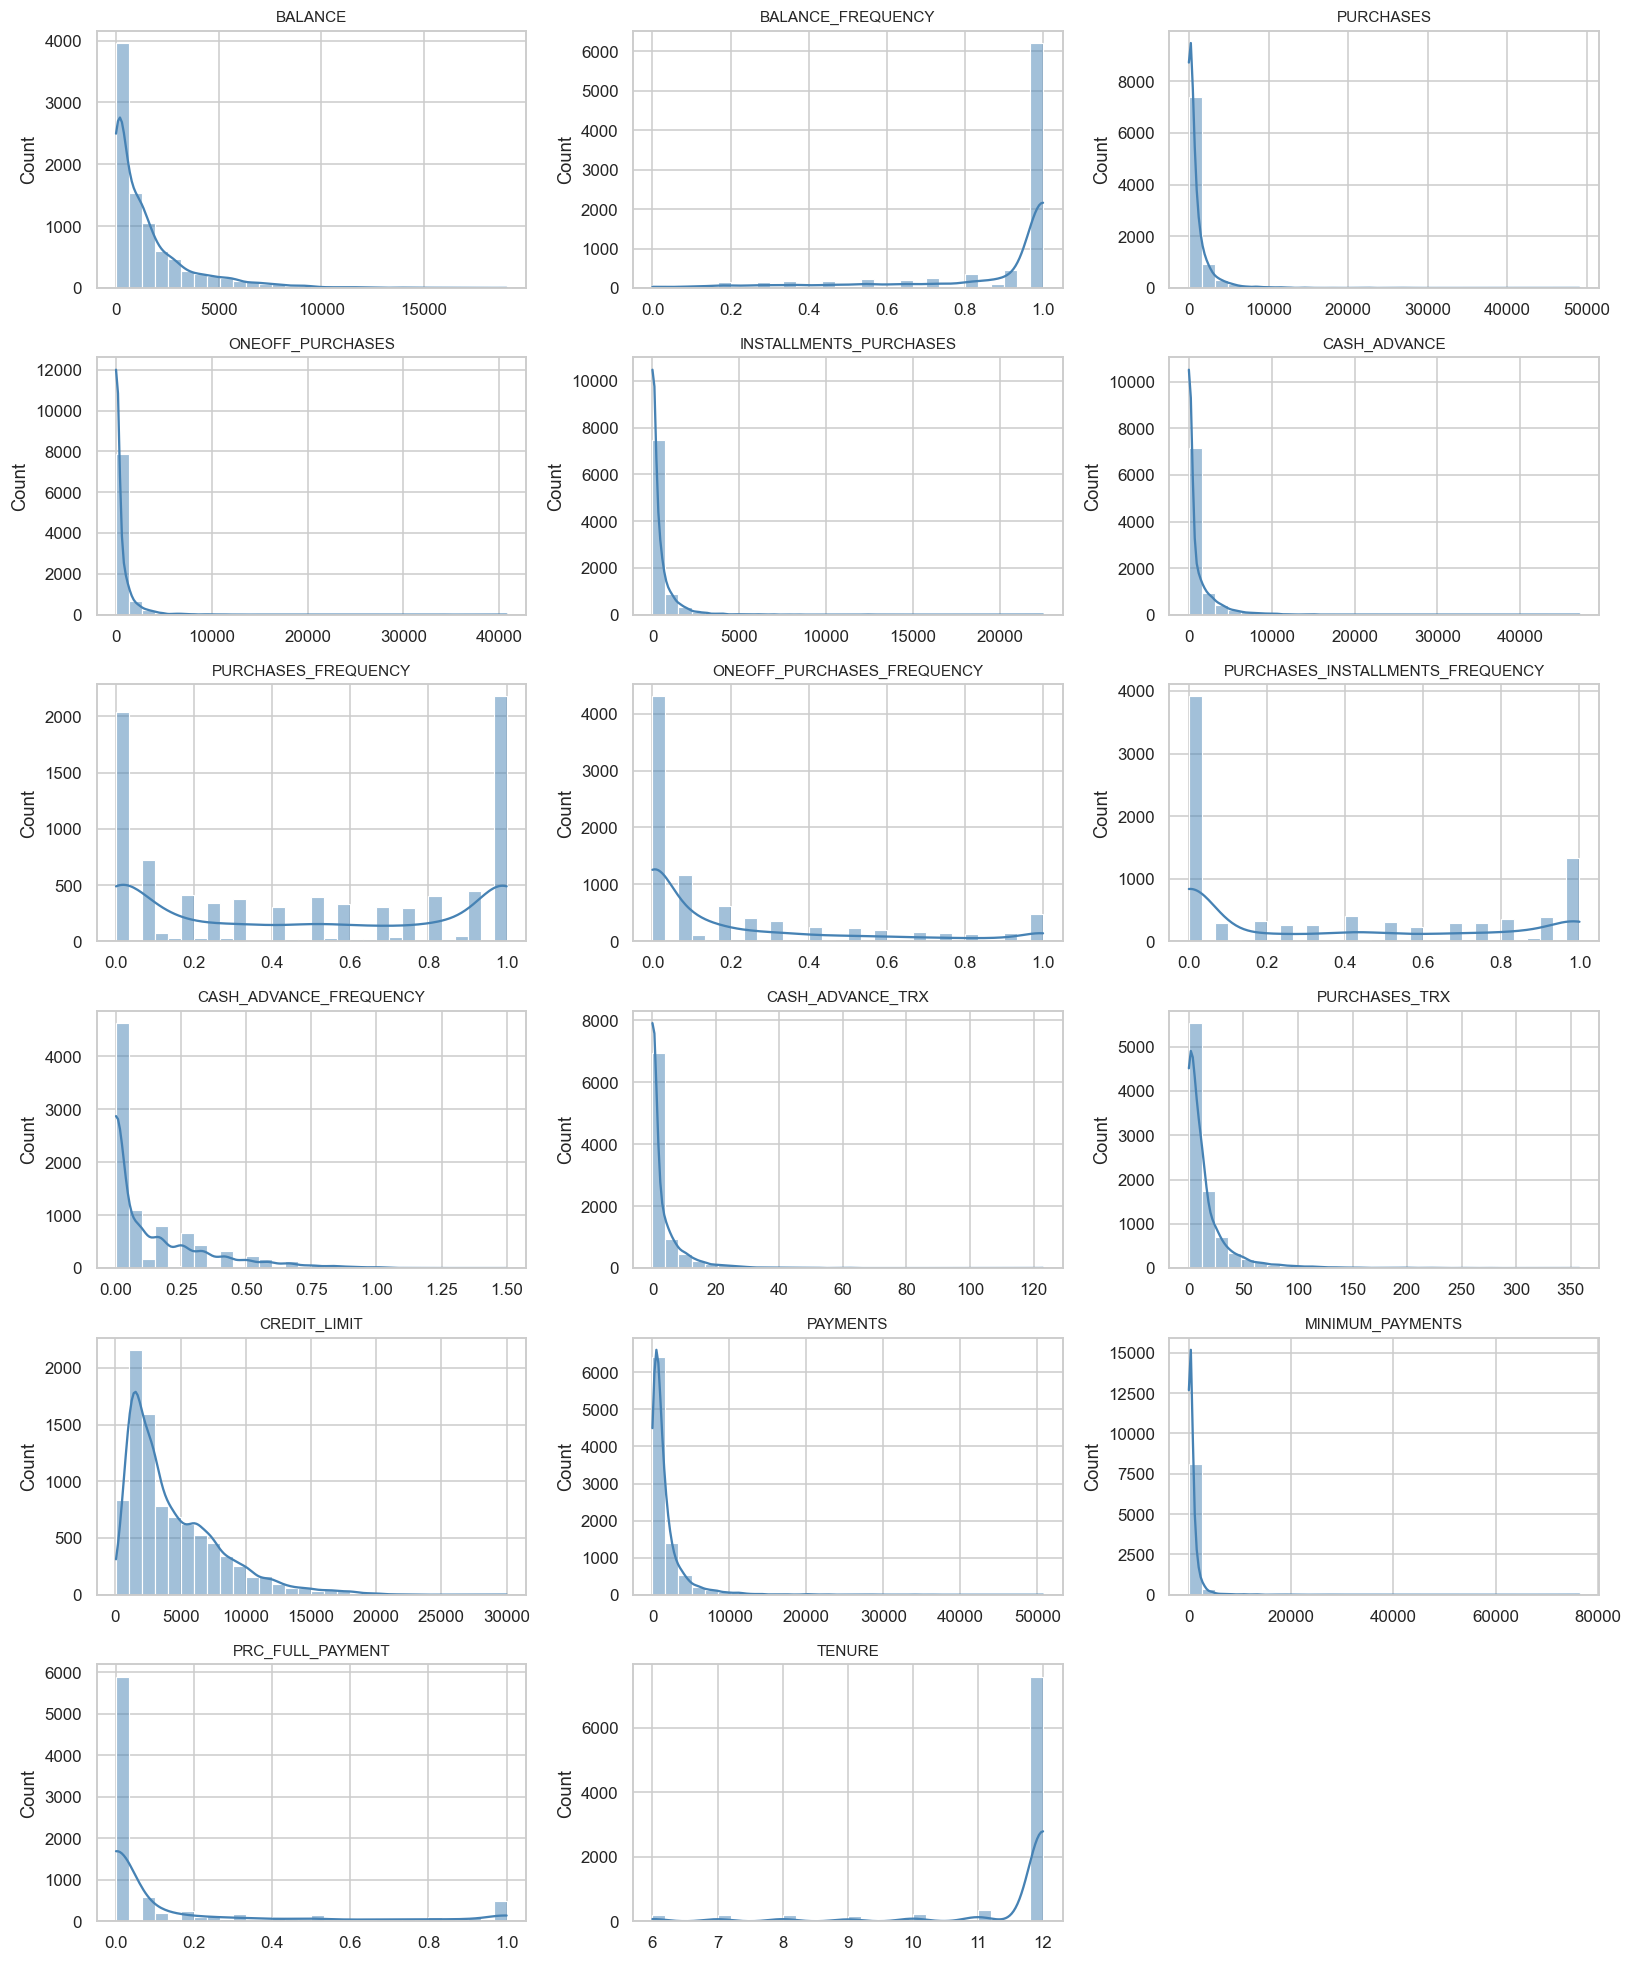

In [22]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

fig, axes = plt.subplots(6, 3, figsize=(15, 18))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], bins=30, color='steelblue')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')

for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### Distribution observations

- Most dollar amount features (`BALANCE`, `PURCHASES`, `ONEOFF_PURCHASES`, `CASH_ADVANCE`, `PAYMENTS`) are heavily right-skewed with a long tail. Most customers spend smaller amounts, and a small number of customers spend a lot.
- Frequencies like `BALANCE_FREQUENCY` and `PURCHASES_FREQUENCY` have peaks at 0 and 1.
- `TENURE` is 12 for the vast majority of users (over 80%).


### 3.2 Correlation heatmap

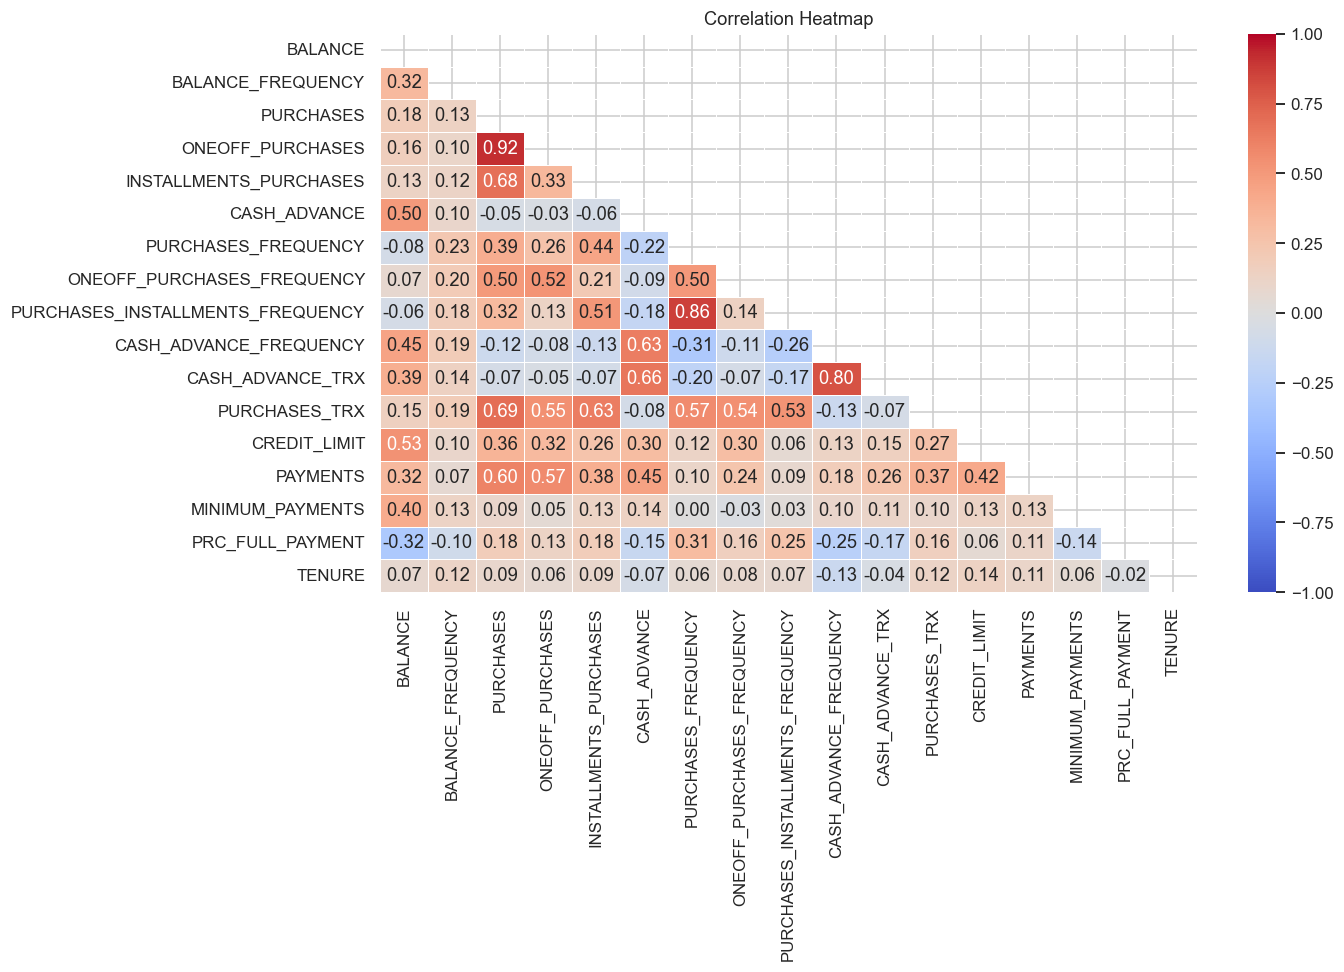

In [23]:
plt.figure(figsize=(13, 9))
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


### Correlation observations

- `PURCHASES` has strong correlation with `ONEOFF_PURCHASES` (0.91) and `PURCHASES_TRX` (0.69).
- `PURCHASES_FREQUENCY` correlates with `PURCHASES_INSTALLMENTS_FREQUENCY` (0.86).
- `CASH_ADVANCE` and `PURCHASES` have almost no correlation (-0.05), which indicates that users who take cash advances are generally a different group from regular shoppers.


### 3.3 Feature relationships
We look at how purchases, balance, cash advance, and payments interact.


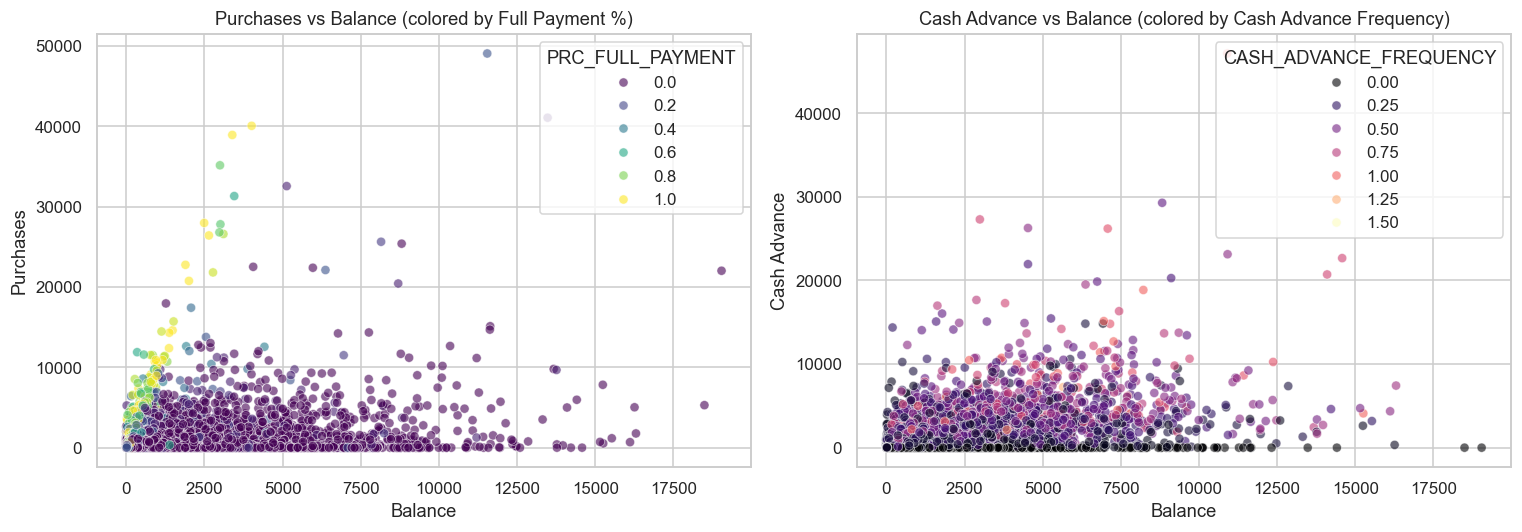

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Purchases vs Balance
sns.scatterplot(data=df, x='BALANCE', y='PURCHASES', hue='PRC_FULL_PAYMENT', palette='viridis', alpha=0.6, ax=axes[0])
axes[0].set_title('Purchases vs Balance (colored by Full Payment %)')
axes[0].set_xlabel('Balance')
axes[0].set_ylabel('Purchases')

# Cash Advance vs Balance
sns.scatterplot(data=df, x='BALANCE', y='CASH_ADVANCE', hue='CASH_ADVANCE_FREQUENCY', palette='magma', alpha=0.6, ax=axes[1])
axes[1].set_title('Cash Advance vs Balance (colored by Cash Advance Frequency)')
axes[1].set_xlabel('Balance')
axes[1].set_ylabel('Cash Advance')

plt.tight_layout()
plt.show()


### Scatter plot observations

- Customers with high purchases mostly keep lower balances and have higher full payment rates.
- High cash advances are associated with higher balances and frequent cash transactions.


## 4. Data cleaning and feature engineering

### 4.1 Missing values and dropping ID
- We drop `CUST_ID` because it is an arbitrary string.
- We fill the missing values in `MINIMUM_PAYMENTS` and `CREDIT_LIMIT` with their medians because the features are right-skewed.


In [25]:
df_clean = df.drop(columns=['CUST_ID']).copy()

df_clean['MINIMUM_PAYMENTS'] = df_clean['MINIMUM_PAYMENTS'].fillna(df_clean['MINIMUM_PAYMENTS'].median())
df_clean['CREDIT_LIMIT'] = df_clean['CREDIT_LIMIT'].fillna(df_clean['CREDIT_LIMIT'].median())

print("Missing values after imputation:", df_clean.isnull().sum().sum())


Missing values after imputation: 0


### 4.2 Feature engineering
We create 3 ratio features that represent customer behavior better than raw dollar amounts:
1. `BALANCE_TO_CREDIT_LIMIT`: Credit utilization ratio. High values indicate customers close to maxing out their card.
2. `PURCHASE_TO_CREDIT_LIMIT`: Spending relative to their credit line.
3. `PAYMENT_TO_MIN_PAYMENT`: Ratio of payments made to minimum required payment. Indicates if they pay more than the minimum.

We add 1 to the denominator to avoid division by zero.


In [26]:
df_feat = df_clean.copy()

df_feat['BALANCE_TO_CREDIT_LIMIT'] = df_feat['BALANCE'] / (df_feat['CREDIT_LIMIT'] + 1)
df_feat['PURCHASE_TO_CREDIT_LIMIT'] = df_feat['PURCHASES'] / (df_feat['CREDIT_LIMIT'] + 1)
df_feat['PAYMENT_TO_MIN_PAYMENT'] = df_feat['PAYMENTS'] / (df_feat['MINIMUM_PAYMENTS'] + 1)

df_feat[['BALANCE_TO_CREDIT_LIMIT', 'PURCHASE_TO_CREDIT_LIMIT', 'PAYMENT_TO_MIN_PAYMENT']].describe().T[['mean', '50%', 'max']]


,mean,50%,max
BALANCE_TO_CREDIT_LIMIT,0.388663,0.302493,15.597991
PURCHASE_TO_CREDIT_LIMIT,0.262461,0.117186,8.582727
PAYMENT_TO_MIN_PAYMENT,6.390555,2.016643,1863.850036


### 4.3 Log transform and scaling
Because amounts span multiple orders of magnitude, we apply `np.log1p` to reduce skewness and then apply `StandardScaler`.


In [27]:
# Log transform followed by standard scaling
df_log = np.log1p(df_feat)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_log)

print("Preprocessed feature matrix shape:", X_scaled.shape)


Preprocessed feature matrix shape: (8950, 20)


## 5. Model 1 - K-Means Clustering

### 5.1 Choosing k with Elbow method and Silhouette score
We test $k$ from 2 to 10 and record inertia, Silhouette score, and Davies-Bouldin index.


In [28]:
k_values = list(range(2, 11))
inertias = []
sil_scores = []
db_scores = []
ch_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_scaled, labels))


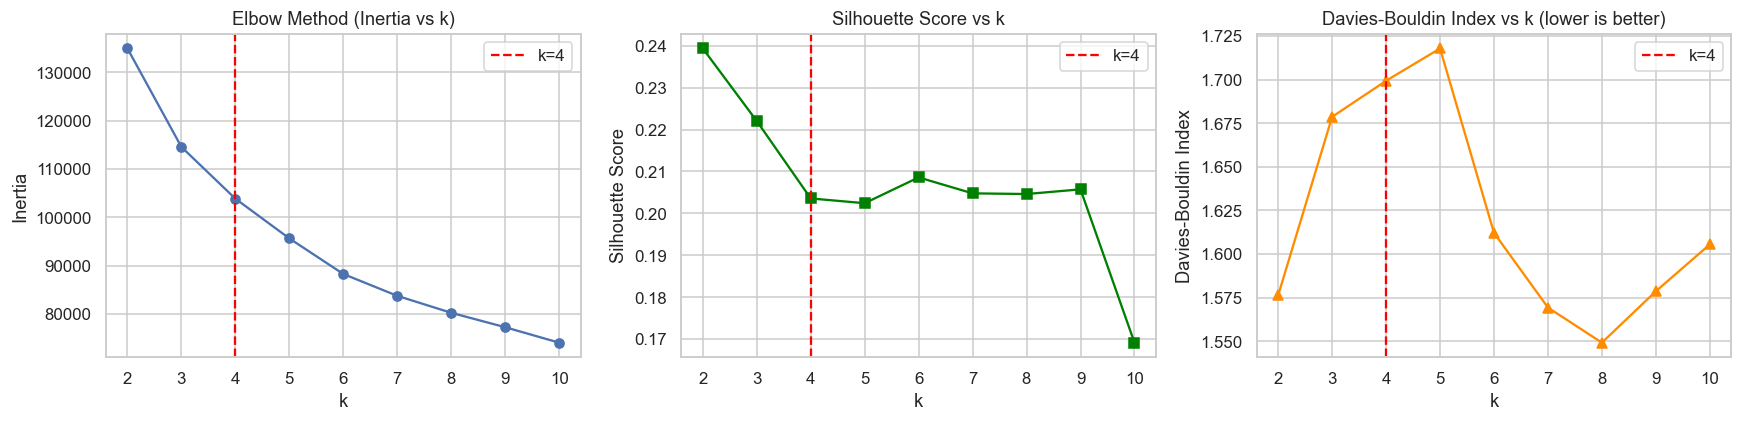

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Elbow curve
axes[0].plot(k_values, inertias, marker='o')
axes[0].axvline(4, color='red', linestyle='--', label='k=4')
axes[0].set_title('Elbow Method (Inertia vs k)')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[0].legend()

# Silhouette score
axes[1].plot(k_values, sil_scores, marker='s', color='green')
axes[1].axvline(4, color='red', linestyle='--', label='k=4')
axes[1].set_title('Silhouette Score vs k')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()

# Davies-Bouldin index (lower is better)
axes[2].plot(k_values, db_scores, marker='^', color='darkorange')
axes[2].axvline(4, color='red', linestyle='--', label='k=4')
axes[2].set_title('Davies-Bouldin Index vs k (lower is better)')
axes[2].set_xlabel('k')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].legend()

plt.tight_layout()
plt.show()


### Observations on k selection

- The elbow curve shows an elbow around $k = 4$, after which inertia drops more slowly.
- Silhouette score peaks around $k = 4$ and $k = 5$.
- We choose $k = 4$ because it gives a good balance between separation metrics and interpretable customer groups.


### 5.2 Training K-Means with k=4 and evaluating metrics

In [30]:
k_optimal = 4

kmeans = KMeans(n_clusters=k_optimal, random_state=RANDOM_STATE, n_init=15)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Metrics required by the rubric
sil = silhouette_score(X_scaled, kmeans_labels)
db = davies_bouldin_score(X_scaled, kmeans_labels)
ch = calinski_harabasz_score(X_scaled, kmeans_labels)

results = pd.DataFrame([{
    'Model': 'K-Means (k=4)',
    'Silhouette Score': round(sil, 4),
    'Davies-Bouldin Index': round(db, 4),
    'Calinski-Harabasz Index': round(ch, 2),
    'Inertia': round(kmeans.inertia_, 2)
}])
results


,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Inertia
0,K-Means (k=4),0.2035,1.6991,2158.58,103836.14


## 6. Cluster visualisations (PCA and t-SNE)

The rubric requires a PCA 2D scatter plot with cluster colors and encourages a t-SNE plot.


In [31]:
# PCA reduction to 2 components
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

var = pca.explained_variance_ratio_
print(f"Explained variance: PC1 = {var[0]*100:.1f}%, PC2 = {var[1]*100:.1f}%, Total = {sum(var)*100:.1f}%")

# t-SNE on a sample of 3000 points
np.random.seed(RANDOM_STATE)
sample_idx = np.random.choice(len(X_scaled), size=3000, replace=False)
tsne = TSNE(n_components=2, perplexity=35, random_state=RANDOM_STATE, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled[sample_idx])
tsne_labels = kmeans_labels[sample_idx]


Explained variance: PC1 = 33.0%, PC2 = 20.7%, Total = 53.7%


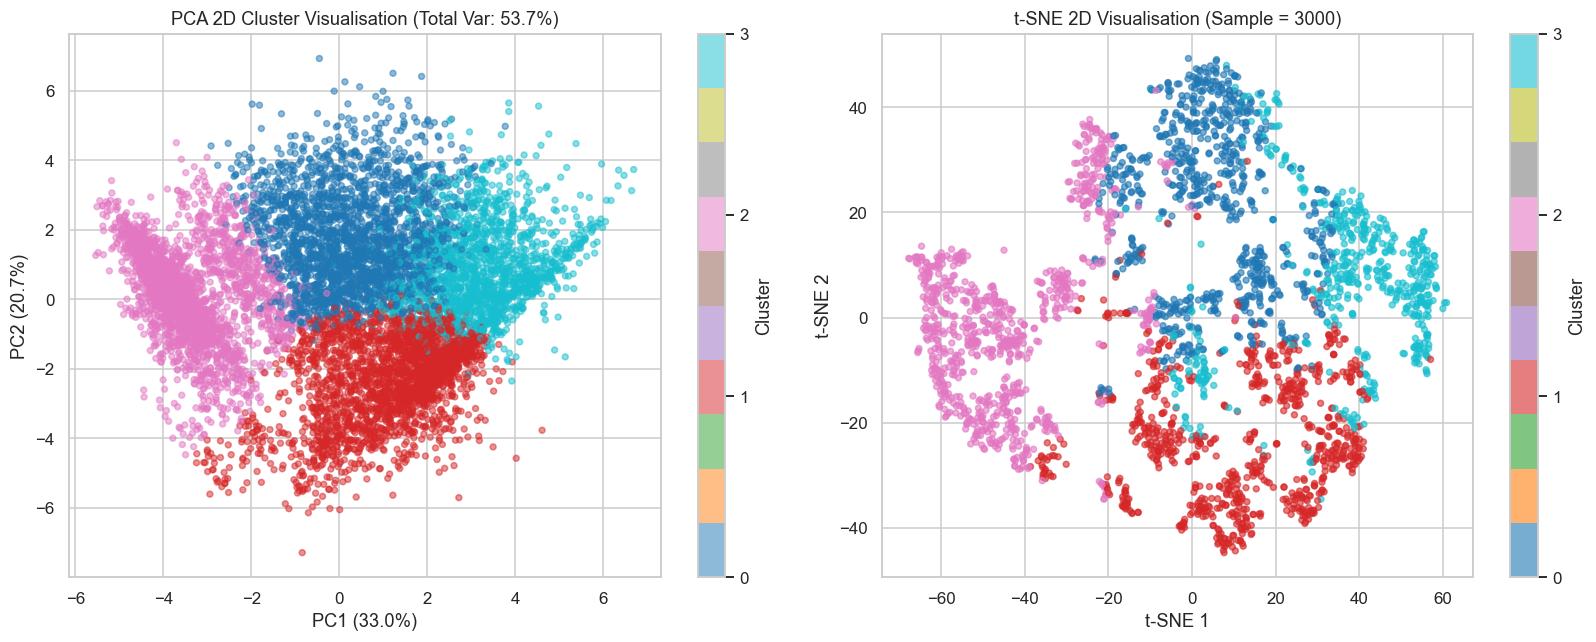

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# PCA plot
scatter_pca = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='tab10', s=15, alpha=0.5)
axes[0].set_title(f'PCA 2D Cluster Visualisation (Total Var: {sum(var)*100:.1f}%)')
axes[0].set_xlabel(f'PC1 ({var[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({var[1]*100:.1f}%)')
plt.colorbar(scatter_pca, ax=axes[0], ticks=range(k_optimal), label='Cluster')

# t-SNE plot
scatter_tsne = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=tsne_labels, cmap='tab10', s=15, alpha=0.6)
axes[1].set_title('t-SNE 2D Visualisation (Sample = 3000)')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
plt.colorbar(scatter_tsne, ax=axes[1], ticks=range(k_optimal), label='Cluster')

plt.tight_layout()
plt.show()


### Visualisation observations

- On PCA, the 4 clusters separate into distinct regions. PC1 separates overall activity (high spenders vs inactive users), while PC2 separates cash advance / loan users from regular purchase users.
- t-SNE confirms clear group separation without heavy mixing.


## 7. Cluster profiling and customer segments

We look at the average values of the original unscaled features for each cluster to understand who each group is.


In [33]:
df_profile = df_feat.copy()
df_profile['Cluster'] = kmeans_labels

summary = df_profile.groupby('Cluster').agg({
    'BALANCE': ['count', 'mean'],
    'PURCHASES': 'mean',
    'CASH_ADVANCE': 'mean',
    'PURCHASES_FREQUENCY': 'mean',
    'CREDIT_LIMIT': 'mean',
    'PAYMENTS': 'mean',
    'PRC_FULL_PAYMENT': 'mean',
    'BALANCE_TO_CREDIT_LIMIT': 'mean'
}).round(2)

summary.columns = [
    'Count', 'Avg Balance', 'Avg Purchases', 'Avg Cash Advance', 
    'Purchase Freq', 'Credit Limit', 'Avg Payments', 'Full Payment %', 'Utilization'
]
summary['Share %'] = (summary['Count'] / len(df_profile) * 100).round(1)
summary


,Count,Avg Balance,Avg Purchases,Avg Cash Advance,Purchase Freq,Credit Limit,Avg Payments,Full Payment %,Utilization,Share %
Cluster,,,,,,,,,,
0,2281,2715.65,1192.06,1347.55,0.69,4626.74,1971.10,0.02,0.66,25.5
1,2451,118.02,399.46,43.84,0.52,3500.72,662.15,0.28,0.05,27.4
2,2574,2292.44,45.71,2076.24,0.03,4170.64,1675.82,0.03,0.61,28.8
3,1644,983.96,3140.44,143.21,0.88,6298.50,3089.46,0.35,0.18,18.4


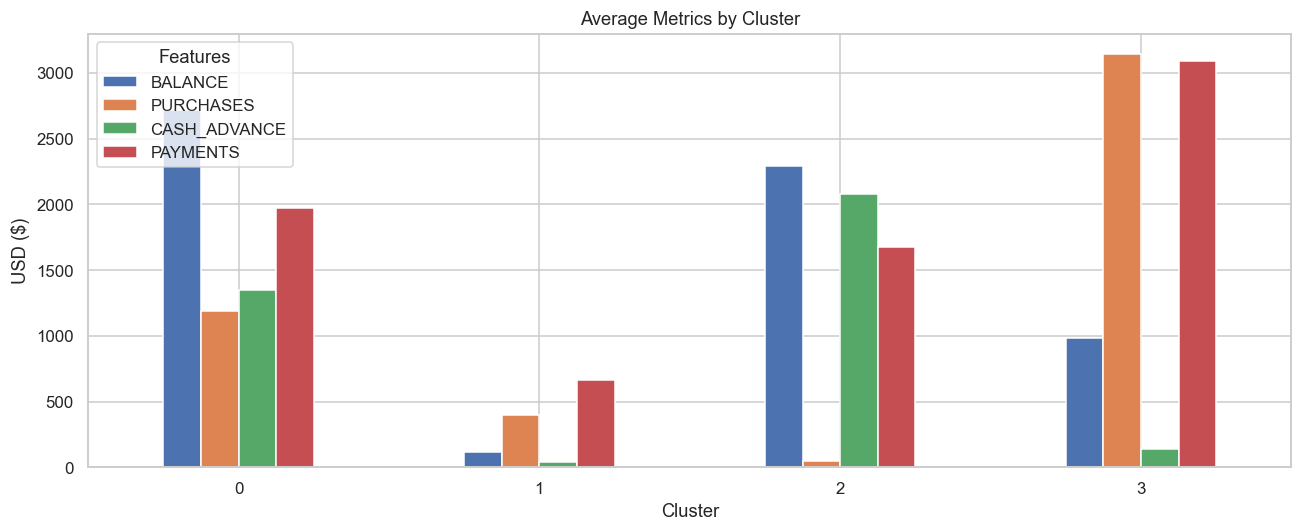

In [34]:
# Bar plot comparing main financial features across clusters
key_cols = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'PAYMENTS']
df_profile.groupby('Cluster')[key_cols].mean().plot(kind='bar', figsize=(12, 5))
plt.title('Average Metrics by Cluster')
plt.ylabel('USD ($)')
plt.xticks(rotation=0)
plt.legend(title='Features')
plt.tight_layout()
plt.show()


### Segment summary

- **Cluster 0 (Low activity / Inactive):** Low balance, low purchases, low payments. These are mostly dormant cards.
- **Cluster 1 (Active spenders):** Highest purchases and payments, high credit limit, frequent usage. Good candidates for premium cards and rewards.
- **Cluster 2 (Cash advance borrowers):** High cash advances, high balance, high credit utilization. They use the card for borrowing rather than purchases.
- **Cluster 3 (Installment buyers):** Moderate purchases, low cash advance, consistent payments.


## 8. Saving the model

In [35]:
import os
import joblib

os.makedirs('models', exist_ok=True)

joblib.dump(scaler, 'models/clustering_scaler.pkl')
joblib.dump(kmeans, 'models/kmeans_model.pkl')
print("Saved models/clustering_scaler.pkl and models/kmeans_model.pkl")


Saved models/clustering_scaler.pkl and models/kmeans_model.pkl
